# Adversarial Search: Solving Tic-Tac-Toe with Pure Monte Carlo Search

## Introduction 

Multiplayer games can be implemented as:
1. Nondeterministic actions: The opponent is seen as part of an environment with nondeterministic actions. Non-determinism is the result of the unknown opponent's moves. 
2. Optimal Decisions: Minimax search (search complete game tree) and alpha-beta pruning.
3. Heuristic Alpha-Beta Tree Search: Cut off tree search and use heuristic to estimate state value. 
4. __Monte Carlo Search:__ Simulate playouts to estimate state value. 

Here we will implement search for Tic-Tac-Toe (see [rules](https://en.wikipedia.org/wiki/Tic-tac-toe)). The game is a __zero-sum game__: Win by x results in +1, win by o in -1 and a tie has a value of 0. Max plays x and tries to maximize the outcome while Min plays o and tries to minimize the outcome.   

We will implement
* Pure Monte Carlo search

The code for the basic functions used for search are implemented in [tictactoe.py](tictactoe.py).

In [1]:
# download if missing
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("tictactoe.py", ".")

In [2]:
from tictactoe import empty_board, actions, result, terminal, utility, other, show_board
from tictactoe import random_player, play 

%precision 3

'%.3f'

# Pure Monte Carlo Search

See AIMA page 161ff. 

We implement a extremely simplified version.

For the current state: 
1. Simulate $N$ random playouts for each possible action and 
2. pick the action with the highest average utility.

__Important note:__ we use here a random playout policy, which ends up creating just a randomized search that works fine for this toy problem. For real applications you need to extend the code with
1. a good __playout policy__ (e.g., learned by self-play) and 
2. a __selection strategy__ (e.g., UCB1).

## Simulate playouts

In [3]:
import numpy as np

def playout(state, action, player = 'x'):
    """Perform a random playout starting with the given action on the given board 
    and return the utility of the finished game."""
    state = result(state, player, action)
    current_player = other(player)
    
    while(True):
        # reached terminal state?
        u = utility(state, player)
        if u is not None: return(u)
        
        # we use a random playout policy
        a = np.random.choice(actions(state))
        state = result(state, current_player, a)
        #print(state)
        
        # switch between players
        current_player = other(current_player)


# Playout for action 0 (top-left corner)
board = empty_board()
print(playout(board, 0))
print(playout(board, 0))
print(playout(board, 0))
print(playout(board, 0))
print(playout(board, 0))

1
1
0
-1
-1


In [4]:
def playouts(board, action, player = 'x', N = 100):
    """Perform N playouts following the given action for the given board."""
    return [ playout(board, action, player) for i in range(N) ]

u = playouts(board, 0)
print("Playout results:", u)

print(f"mean utility: {np.mean(u)}")

p_win = sum(np.array(u) == +1)/len(u)
p_loss = sum(np.array(u) == -1)/len(u)
p_draw = sum(np.array(u) == 0)/len(u)
print(f"win probability: {p_win}")
print(f"loss probability: {p_loss}")
print(f"draw probability: {p_draw}")

Playout results: [1, -1, 1, 1, 1, 1, 1, 0, -1, 1, 1, 0, 0, 1, 1, 1, -1, 0, -1, -1, -1, 1, 1, 1, -1, 1, -1, 1, 1, 1, 1, 1, 1, -1, 1, 0, 1, 1, 1, -1, 0, -1, 0, 1, -1, 1, -1, 1, 0, 0, 1, -1, 1, 0, 0, 1, 0, -1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, -1, 0, -1, -1, 1, 1, -1, 1, 1, -1, 1, 1, 1, 1, 1, -1, 1, -1, 1, 1, 1, 0, -1, 1, -1, -1, 1, 1, -1, 1, -1]
mean utility: 0.3
win probability: 0.57
loss probability: 0.27
draw probability: 0.16


**Nhận xét – `playout()` và `playouts()`.** Mỗi `playout` đi nước đầu tiên được chỉ định rồi cho cả hai bên chơi ngẫu nhiên đến hết ván, trả về +1/0/−1 theo góc nhìn của người đi nước đầu; `playouts` lặp lại `N` lần để lấy mẫu. Điểm trung bình của các mẫu là **ước lượng Monte Carlo** cho giá trị của nước đi. Với nước đi vào góc 0, điểm trung bình thu được dương và dao động quanh giá trị chính xác 0,343 khi hai bên chơi ngẫu nhiên (tính bằng quy hoạch động ở phần bổ sung phía dưới); với N = 100 sai số chuẩn khoảng 0,09 nên mỗi lần chạy cho kết quả hơi khác nhau. Điểm dương cho thấy lợi thế của người đi trước trong một ván chơi ngẫu nhiên.

__Note:__ This shows that the player who goes first has a significant advantage in __pure random play.__ Real players do not play randomly, a better playout policy would be good.

## Pure Monte Carlo Search

In [5]:
import math

DEBUG = 1


def pmcs(board, N = 100, player = 'x'):
    """Pure Monte Carlo Search. Returns the action that has the largest average utility.
    The N playouts are evenly divided between the possible actions."""
    global DEBUG
    
    acts = actions(board)
    n = math.floor(N/len(acts))
    if DEBUG >= 1: print(f"Actions: {acts} ({N} total playouts = {n} playouts per action)")
    
    ps = { i : np.mean(playouts(board, i, player, N = n)) for i in acts }
    if DEBUG >= 1: display(ps)
        
    action = max(ps, key=ps.get)
    return action

board = empty_board()
display(board)
%time print(pmcs(board))

print()
print("10000 playouts give a better utility estimate.")
%time print(pmcs(board, N = 10000))

[' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ']

Actions: [0, 1, 2, 3, 4, 5, 6, 7, 8] (100 total playouts = 11 playouts per action)


{0: 0.364,
 1: 0.545,
 2: 0.182,
 3: 0.455,
 4: 0.818,
 5: 0.364,
 6: 0.182,
 7: -0.182,
 8: 0.636}

4
CPU times: user 19 ms, sys: 15.6 ms, total: 34.6 ms
Wall time: 34.5 ms

10000 playouts give a better utility estimate.
Actions: [0, 1, 2, 3, 4, 5, 6, 7, 8] (10000 total playouts = 1111 playouts per action)


{0: 0.328,
 1: 0.228,
 2: 0.333,
 3: 0.203,
 4: 0.519,
 5: 0.221,
 6: 0.342,
 7: 0.188,
 8: 0.321}

4
CPU times: user 2.42 s, sys: 61.6 ms, total: 2.48 s
Wall time: 2.49 s


Looks like the center and the corners are a lot better.

## Some Tests

### x is about to win (play 8)


Board:


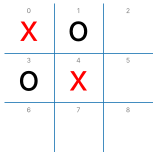


Actions: [2, 5, 6, 7, 8] (100 total playouts = 20 playouts per action)


{2: 0.800, 5: 0.450, 6: 0.800, 7: 0.750, 8: 1.000}

8

CPU times: user 22 ms, sys: 119 μs, total: 22.2 ms
Wall time: 22.7 ms


In [6]:
board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'

print("Board:")
show_board(board)

print()
%time display(pmcs(board))

**Nhận xét – x sắp thắng.** Ô 8 hoàn thành đường chéo 0‑4‑8 nên *mọi* playout bắt đầu từ ô 8 đều thắng ngay: điểm trung bình đúng bằng 1,0 và PMCS chọn ô 8. Ô 2 và ô 6 tạo đe dọa kép (fork) nên cũng thắng chắc nếu chơi đúng, nhưng vì các nước sau của x trong playout là ngẫu nhiên nên điểm kỳ vọng thấp hơn (≈ 0,83); ô 5 và ô 7 không tạo đe dọa mới nên kỳ vọng thấp nhất (≈ 0,67). Với 20 playout cho mỗi nước, sai số chuẩn khoảng ±0,15 nên thứ tự của các nước phụ có thể đảo trong một lần chạy cụ thể, nhưng ô 8 luôn đứng đầu. Xếp hạng phù hợp với đáp án Minimax (các ô 2, 6, 8 đều dẫn đến thắng).

### o is about to win

Board:


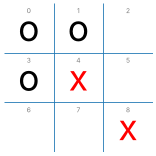


Actions: [2, 5, 6, 7] (100 total playouts = 25 playouts per action)


{2: 0.040, 5: -0.680, 6: 0.040, 7: -0.520}

2

CPU times: user 13.1 ms, sys: 45 μs, total: 13.2 ms
Wall time: 13.2 ms

Actions: [2, 5, 6, 7] (1000 total playouts = 250 playouts per action)


{2: 0.008, 5: -0.760, 6: 0.048, 7: -0.680}

6

CPU times: user 97 ms, sys: 7.7 ms, total: 105 ms
Wall time: 101 ms


In [7]:
board = empty_board() 
board[0] = 'o'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'
board[8] = 'x'

print("Board:")
show_board(board)

print()
%time display(pmcs(board))

print()
%time display(pmcs(board, N = 1000))

**Nhận xét – o sắp thắng.** Đây là thế cờ thua: o đang có hai đe dọa (ô 2 hoàn thành hàng 0‑1‑2, ô 6 hoàn thành cột 0‑3‑6) nên về lý thuyết mọi nước của x đều thua. PMCS vẫn phân biệt được nước "ít tệ hơn": ô 2 và ô 6 (chặn một đe dọa) có điểm kỳ vọng ≈ 0 trong khi ô 5 và ô 7 (bỏ qua cả hai đe dọa) chỉ ≈ −0,67 (giá trị chính xác khi hai bên chơi ngẫu nhiên), vì o chơi ngẫu nhiên vẫn có thể bỏ lỡ nước thắng còn lại. Ô 2 và ô 6 đối xứng qua đường chéo chính nên có giá trị kỳ vọng bằng nhau – PMCS chọn 2 hay 6 chỉ là ngẫu nhiên giữa hai nước tương đương (dao động vô hại). Tăng N từ 100 lên 1000 làm các điểm số ổn định hơn (độ nhiễu giảm ≈ √10 lần) nhưng thời gian chạy tăng ≈ 10 lần.

### x can draw if it chooses 7

Board:


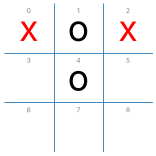


Actions: [3, 5, 6, 7, 8] (100 total playouts = 20 playouts per action)


{3: -0.300, 5: -0.350, 6: -0.300, 7: 0.250, 8: -0.350}

7

CPU times: user 17.1 ms, sys: 7.96 ms, total: 25.1 ms
Wall time: 25.8 ms


In [8]:
board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[2] = 'x'
board[4] = 'o'

print("Board:")
show_board(board)

print()
%time display(pmcs(board))

**Nhận xét – x cần tìm đường hòa.** o đang đe dọa cột 1‑4‑7 nên nước duy nhất không thua là **ô 7**. Tuy nhiên PMCS đo "kết quả trung bình khi cả hai bên chơi ngẫu nhiên", *không phải* giá trị khi đối thủ chơi tối ưu: kỳ vọng chính xác của ô 7 là +0,17, còn các nước thua là −0,17 (ô 3, 5) và −0,33 (ô 6, 8) – khoảng cách chỉ 0,33–0,5. Với N = 100 (≈ 20 playout/nước) sai số chuẩn của mỗi điểm số khoảng 0,2, tương đương khoảng cách này, nên việc chọn đúng ô 7 không được đảm bảo trong mỗi lần chạy (có lần đúng, có lần sai). Thí nghiệm lặp lại 30 lần ở phần bổ sung đo chính xác tỉ lệ chọn đúng ô 7 theo N (N = 10 gần như đoán mò, N = 100 đúng phần lớn số lần, N = 1000 đúng gần như luôn luôn).

### Empty board: Only a draw an be guaranteed

Board:


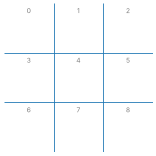


Actions: [0, 1, 2, 3, 4, 5, 6, 7, 8] (5000 total playouts = 555 playouts per action)


{0: 0.382,
 1: 0.191,
 2: 0.364,
 3: 0.232,
 4: 0.508,
 5: 0.196,
 6: 0.342,
 7: 0.177,
 8: 0.360}

4

CPU times: user 1.48 s, sys: 70.4 ms, total: 1.55 s
Wall time: 1.55 s


In [9]:
board = empty_board() 

print("Board:")
show_board(board)

print()
%time display(pmcs(board, N = 5000))

**Nhận xét – bàn cờ rỗng (N = 5000).** Ô giữa (4) có điểm trung bình cao nhất (≈ 0,5), các góc 0, 2, 6, 8 ở mức trung bình (≈ 0,3–0,4) và các cạnh 1, 3, 5, 7 thấp nhất (≈ 0,1–0,3). Các giá trị này khớp với kỳ vọng chính xác khi hai bên chơi ngẫu nhiên (0,5 / 0,343 / 0,2 – tính ở phần bổ sung) trong phạm vi sai số lấy mẫu (khoảng ±0,04 với 555 playout/nước). PMCS "tự học" được rằng ô giữa và các góc là nước mở đầu tốt mà **không cần hàm heuristic thủ công** – ưu điểm chính của phương pháp Monte Carlo. Lưu ý đây là giá trị *trước đối thủ ngẫu nhiên*; trước đối thủ tối ưu mọi nước mở đầu đều chỉ đảm bảo hòa.

### A bad situation

Board:


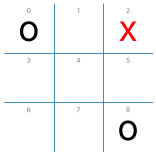


Actions: [1, 3, 4, 5, 6, 7] (100 total playouts = 16 playouts per action)


{1: -0.875, 3: -0.625, 4: -0.125, 5: -0.750, 6: -0.500, 7: -0.375}

4

CPU times: user 27.1 ms, sys: 0 ns, total: 27.1 ms
Wall time: 28.6 ms


In [10]:
board = empty_board() 
board[0] = 'o'
board[2] = 'x'
board[8] = 'o'

print("Board:")
show_board(board)

print()
%time display(pmcs(board))

**Nhận xét – tình huống bất lợi.** PMCS chọn ô 4: đây là nước *bắt buộc* (chặn đường chéo 0‑4‑8 của o) và đồng thời tạo đe dọa ở ô 6. Nếu o chơi tối ưu (chặn ô 6) thì o tạo được thế đôi (ô 3 và ô 7) và x thua, nên về lý thuyết mọi nước đều thua; nhưng o ngẫu nhiên chỉ chặn đúng ô 6 với xác suất 1/5, vì vậy kỳ vọng của ô 4 là +0,17 – cao nhất – trong khi các nước còn lại chỉ từ −0,2 đến −0,67. Với chỉ 16 playout/nước, điểm của ô 4 trong một lần chạy có thể dao động quanh 0 (sai số chuẩn ≈ 0,2) nhưng vẫn cao hơn các nước còn lại. Đây là cách PMCS "tận dụng sai lầm của đối thủ ngẫu nhiên": hiệu quả khi đối thủ yếu nhưng không an toàn trước đối thủ mạnh – hạn chế cố hữu của chính sách playout ngẫu nhiên.

__Note:__ It looks like random player o is very unlikely to block x and take advantage of the trap by playing the bottom left corner!

## Experiments

### Pure Monte Carlo Search vs. Random

In [11]:
def pmcs10_player(board, player = 'x'):
    action = pmcs(board, N = 10, player = player)
    return action

def pmcs100_player(board, player = 'x'):
    action = pmcs(board, N = 100, player = player)
    return action

def pmcs1000_player(board, player = 'x'):
    action = pmcs(board, N = 1000, player = player)
    return action


DEBUG = 1
print("PMCS vs. random:")
display(play(pmcs10_player, random_player, N = 1))

PMCS vs. random:
Actions: [0, 1, 2, 3, 4, 5, 6, 7, 8] (10 total playouts = 1 playouts per action)


{0: 1.000,
 1: 1.000,
 2: 1.000,
 3: 1.000,
 4: 1.000,
 5: -1.000,
 6: 0.000,
 7: -1.000,
 8: -1.000}

Actions: [1, 3, 4, 5, 6, 7, 8] (10 total playouts = 1 playouts per action)


{1: -1.000, 3: -1.000, 4: 1.000, 5: 0.000, 6: 1.000, 7: 1.000, 8: -1.000}

Actions: [1, 3, 5, 6, 8] (10 total playouts = 2 playouts per action)


{1: 1.000, 3: 0.000, 5: 1.000, 6: 1.000, 8: 1.000}

Actions: [3, 6, 8] (10 total playouts = 3 playouts per action)


{3: -1.000, 6: 1.000, 8: 1.000}

{'x': 0, 'o': 1, 'd': 0}

In [12]:
DEBUG = 0
print("PMCS (10) vs. random:")
%time display(play(pmcs10_player, random_player))

print()
print("random vs. PMCS (10)")
%time display(play(random_player, pmcs10_player))

PMCS (10) vs. random:


{'x': 89, 'o': 7, 'd': 4}

CPU times: user 669 ms, sys: 28.6 ms, total: 698 ms
Wall time: 684 ms

random vs. PMCS (10)


{'x': 29, 'o': 64, 'd': 7}

CPU times: user 418 ms, sys: 20.6 ms, total: 439 ms
Wall time: 438 ms


In [13]:
DEBUG = 0
print("PMCS (100) vs. random:")
%time display(play(pmcs100_player, random_player))

print()
print("random vs. PMCS (100)")
%time display(play(random_player, pmcs100_player))

PMCS (100) vs. random:


{'x': 96, 'o': 0, 'd': 4}

CPU times: user 5.99 s, sys: 286 ms, total: 6.28 s
Wall time: 6.25 s

random vs. PMCS (100)


{'x': 12, 'o': 77, 'd': 11}

CPU times: user 4.52 s, sys: 301 ms, total: 4.83 s
Wall time: 4.75 s


In [14]:
DEBUG = 0
print("PMCS (100) vs. PMCS (10):")
%time display(play(pmcs100_player, pmcs10_player))

print()
print("PMCS (10) vs. PMCS (100)")
%time display(play(pmcs10_player, pmcs100_player))

PMCS (100) vs. PMCS (10):


{'x': 88, 'o': 2, 'd': 10}

CPU times: user 6.83 s, sys: 135 ms, total: 6.97 s
Wall time: 6.99 s

PMCS (10) vs. PMCS (100)


{'x': 38, 'o': 46, 'd': 16}

CPU times: user 5.02 s, sys: 187 ms, total: 5.21 s
Wall time: 5.21 s


**Nhận xét – PMCS vs. Random và PMCS vs. PMCS** (các ô gốc không đặt seed nên số liệu dao động vài ván giữa các lần chạy). Với N = 10 (≈ 1 playout cho mỗi nước) quyết định rất nhiễu nhưng PMCS vẫn thắng khoảng 90 % số ván khi đi trước và khoảng 65–70 % khi đi sau trước Random; N = 100 tốt hơn rõ rệt (thắng ≈ 95 % khi đi trước và ≈ 80–90 % khi đi sau) với thời gian lớn hơn ≈ 10 lần. Khi hai PMCS gặp nhau, PMCS(100) đi trước thắng áp đảo PMCS(10) (≈ 88/100 ván); khi PMCS(100) đi sau, chênh lệch thu hẹp đáng kể (PMCS(100) chỉ hơn PMCS(10) từ 0 đến khoảng 25 ván trên 100, kèm nhiều ván hòa) vì lợi thế đi trước của PMCS(10) bù lại một phần chênh lệch sức mạnh. Bảng đầy đủ cho N = 10, 100, 1000 (cả hai vai, có thời gian) ở phần bổ sung bên dưới.

**Note 1:** You can try `pmcs_1000`, but it will take a few minutes to run 100 games.

**Note 2:** The important advantage about Monte Carlo Search is that we do not need to define a heuristic evaluation function to decide what boards are good.

---
# Lab 05 – Bài 5: Thực hành bổ sung (độ ổn định theo N, hội tụ Monte Carlo, bảng PMCS vs. Random với N = 10, 100, 1000)

> Các ô phía trên là nội dung gốc của giảng viên (giữ nguyên); các ô nhận xét (in nghiêng/đậm) được chèn thêm ngay dưới từng thí nghiệm. Phần này thực hiện yêu cầu của Bài 5:
> 1. chạy `pmcs` với **N = 10, 100, 1000** trên cùng các trạng thái kiểm thử và quan sát **độ ổn định** của nước đi và **thời gian chạy**;
> 2. cho `pmcs10_player`, `pmcs100_player` (và `pmcs1000_player`) đấu với `random_player` rồi điền bảng *Số playout N – Tỷ lệ thắng – Tỷ lệ hòa – Tỷ lệ thua – Thời gian – Nhận xét*.

In [15]:
import time, random
from collections import Counter
from functools import lru_cache
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tictactoe
from tictactoe import check_board
from IPython.display import Markdown

DEBUG = 0           # tắt in thông tin của pmcs

def make_board(**cells):
    b = empty_board()
    for symbol, idx in cells.items():
        for i in idx: b[i] = symbol
    return b

# Cùng các trạng thái kiểm thử với phần trên của notebook
TESTS = {
    "X sắp thắng"         : make_board(x=[0, 4], o=[1, 3]),
    "X cần tìm đường hòa" : make_board(x=[0, 2], o=[1, 4]),
    "Tình huống bất lợi"  : make_board(x=[2], o=[0, 8]),
    "O sắp thắng"         : make_board(x=[4, 8], o=[0, 1, 3]),
    "Bàn cờ rỗng"         : empty_board(),
}

# --- Bộ giải Minimax chính xác (có nhớ): CHỈ dùng để đánh giá chất lượng nước đi của PMCS ---
@lru_cache(maxsize=None)
def solve(state, mover):
    g = check_board(list(state))
    if g == 'x': return 1
    if g == 'o': return -1
    if g == 'd': return 0
    vals = []
    for a in tictactoe.actions(list(state)):
        c = list(state); c[a] = mover
        vals.append(solve(tuple(c), other(mover)))
    return max(vals) if mover == 'x' else min(vals)

def action_values(b, mover = 'x'):
    sign = 1 if mover == 'x' else -1
    out = {}
    for a in tictactoe.actions(b):
        c = list(b); c[a] = mover
        out[a] = sign * solve(tuple(c), other(mover))
    return out

def optimal_set(b, mover = 'x'):
    av = action_values(b, mover)
    best = max(av.values())
    return {a for a, v in av.items() if v == best}, len(set(av.values())) > 1   # (các nước tối ưu, thế cờ có phân biệt nước tốt/xấu?)

# --- Giá trị kỳ vọng CHÍNH XÁC (cho x) nếu từ trạng thái đó cả hai bên chơi hoàn toàn ngẫu nhiên ---
@lru_cache(maxsize=None)
def random_value(state, mover):
    g = check_board(list(state))
    if g == 'x': return 1.0
    if g == 'o': return -1.0
    if g == 'd': return 0.0
    acts = tictactoe.actions(list(state))
    tot = 0.0
    for a in acts:
        c = list(state); c[a] = mover
        tot += random_value(tuple(c), other(mover))
    return tot / len(acts)

exact = {a: random_value(tuple('x' if i == a else ' ' for i in range(9)), 'o') for a in range(9)}
print("Kỳ vọng chính xác của điểm trung bình sau nước đầu tiên của x (cả hai bên chơi ngẫu nhiên):")
print({a: round(v, 3) for a, v in exact.items()})

Kỳ vọng chính xác của điểm trung bình sau nước đầu tiên của x (cả hai bên chơi ngẫu nhiên):
{0: 0.343, 1: 0.2, 2: 0.343, 3: 0.2, 4: 0.5, 5: 0.2, 6: 0.343, 7: 0.2, 8: 0.343}


In [16]:
# ---- Thí nghiệm lặp lại: 30 lần chạy pmcs cho mỗi (thế cờ, N) ----
REPEAT = 30
np.random.seed(2026)
rows = []
for name, b in TESTS.items():
    opt, informative = optimal_set(b)
    for N in (10, 100, 1000):
        picks, times = [], []
        for _ in range(REPEAT):
            t0 = time.perf_counter()
            a = pmcs(b, N = N)
            times.append((time.perf_counter() - t0) * 1000)
            picks.append(a)
        cnt = Counter(picks)
        top, freq = cnt.most_common(1)[0]
        rows.append({"Trạng thái": name, "N": N,
                     "Nước hay chọn nhất": top, "Tần suất": f"{freq}/{REPEAT}",
                     "Số nước khác nhau": len(cnt),
                     "Nước tối ưu": sorted(opt) if informative else "mọi nước như nhau",
                     "% chọn nước tối ưu": f"{100 * sum(v for k, v in cnt.items() if k in opt) / REPEAT:.0f}%" if informative else "—",
                     "Thời gian TB (ms)": round(np.mean(times), 2)})
stab = pd.DataFrame(rows)
display(stab)

,Trạng thái,N,Nước hay chọn nhất,Tần suất,Số nước khác nhau,Nước tối ưu,% chọn nước tối ưu,Thời gian TB (ms)
0,X sắp thắng,10,2,19/30,5,"[2, 6, 8]",83%,2.68
1,X sắp thắng,100,8,28/30,2,"[2, 6, 8]",100%,17.50
2,X sắp thắng,1000,8,30/30,1,"[2, 6, 8]",100%,114.42
3,X cần tìm đường hòa,10,5,8/30,5,[7],13%,1.09
4,X cần tìm đường hòa,100,7,24/30,4,[7],80%,9.35
5,X cần tìm đường hòa,1000,7,30/30,1,[7],100%,100.48
6,Tình huống bất lợi,10,4,11/30,6,mọi nước như nhau,—,0.62
7,Tình huống bất lợi,100,4,24/30,2,mọi nước như nhau,—,10.40
8,Tình huống bất lợi,1000,4,30/30,1,mọi nước như nhau,—,108.41
9,O sắp thắng,10,2,15/30,4,mọi nước như nhau,—,0.56


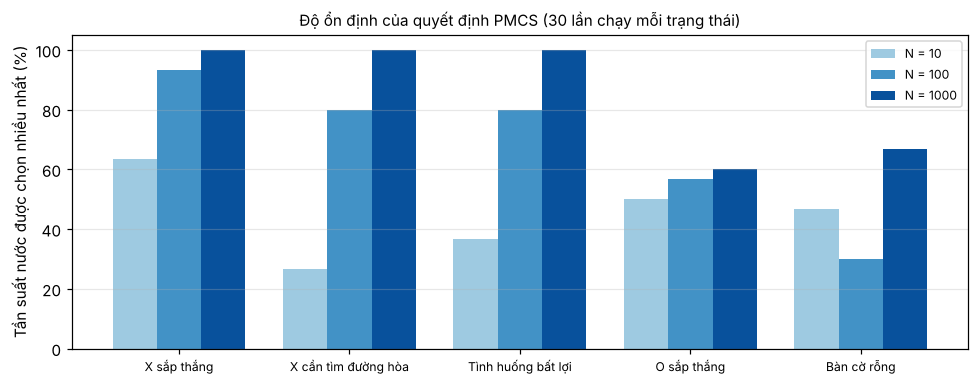

In [17]:
# Biểu đồ: tần suất của nước được chọn nhiều nhất trong 30 lần chạy (càng cao = càng ổn định)
stab["freq"] = stab["Tần suất"].str.split("/").str[0].astype(int) / REPEAT * 100
fig, ax = plt.subplots(figsize = (9, 3.6), dpi = 110)
names = list(TESTS)
w = 0.26
for k, (N, col) in enumerate(zip((10, 100, 1000), ("#9ecae1", "#4292c6", "#08519c"))):
    vals = [stab[(stab["Trạng thái"] == n) & (stab["N"] == N)]["freq"].iloc[0] for n in names]
    ax.bar(np.arange(len(names)) + (k - 1) * w, vals, w, label = f"N = {N}", color = col)
ax.set_xticks(np.arange(len(names))); ax.set_xticklabels(names, fontsize = 8)
ax.set_ylabel("Tần suất nước được chọn nhiều nhất (%)"); ax.set_ylim(0, 105)
ax.set_title("Độ ổn định của quyết định PMCS (30 lần chạy mỗi trạng thái)", fontsize = 10)
ax.legend(fontsize = 8); ax.grid(axis = "y", alpha = .3)
plt.tight_layout(); plt.show()

,Số playout mỗi nước (n),RMSE,RMSE × √n
0,10,0.2526,0.7988
1,100,0.0783,0.7830
2,1000,0.0259,0.8175
3,10000,0.0101,1.0056


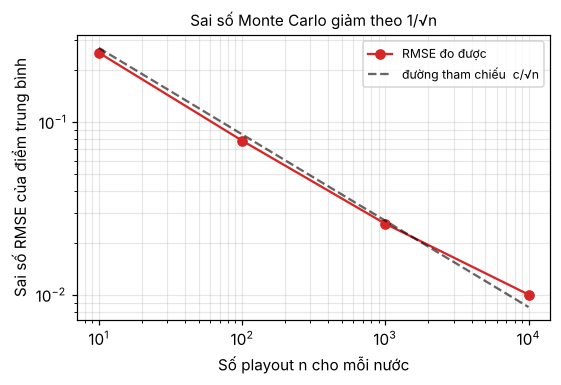

In [18]:
# ---- Hội tụ của ước lượng Monte Carlo: sai số (RMSE) so với giá trị chính xác khi số playout n tăng ----
b0 = empty_board()
classes = {"giữa (ô 4)": 4, "góc (ô 0)": 0, "cạnh (ô 1)": 1}
REPS = {10: 60, 100: 40, 1000: 15, 10000: 4}          # số lần lặp cho mỗi n (để ước lượng RMSE)
np.random.seed(2026)
conv = []
for n, reps in REPS.items():
    errs = []
    for name, a in classes.items():
        for _ in range(reps):
            errs.append(np.mean(playouts(b0, a, 'x', N = n)) - exact[a])
    conv.append({"Số playout mỗi nước (n)": n, "RMSE": float(np.sqrt(np.mean(np.square(errs))))})
conv = pd.DataFrame(conv)
conv["RMSE × √n"] = conv["RMSE"] * np.sqrt(conv["Số playout mỗi nước (n)"])
display(conv.round(4))

fig, ax = plt.subplots(figsize = (5.2, 3.6), dpi = 110)
ax.loglog(conv.iloc[:, 0], conv["RMSE"], "o-", color = "#d62728", label = "RMSE đo được")
ref = conv["RMSE × √n"].mean() / np.sqrt(conv.iloc[:, 0])
ax.loglog(conv.iloc[:, 0], ref, "k--", alpha = .6, label = "đường tham chiếu  c/√n")
ax.set_xlabel("Số playout n cho mỗi nước"); ax.set_ylabel("Sai số RMSE của điểm trung bình")
ax.set_title("Sai số Monte Carlo giảm theo 1/√n", fontsize = 10); ax.grid(alpha = .3, which = "both"); ax.legend(fontsize = 8)
plt.tight_layout(); plt.show()

Có 3,191 thế cờ chưa kết thúc mà các nước đi có giá trị Minimax khác nhau.


,N,% nước tối ưu,Thời gian TB (ms)
0,10,84.0,0.8
1,100,96.0,7.0
2,1000,97.0,68.7


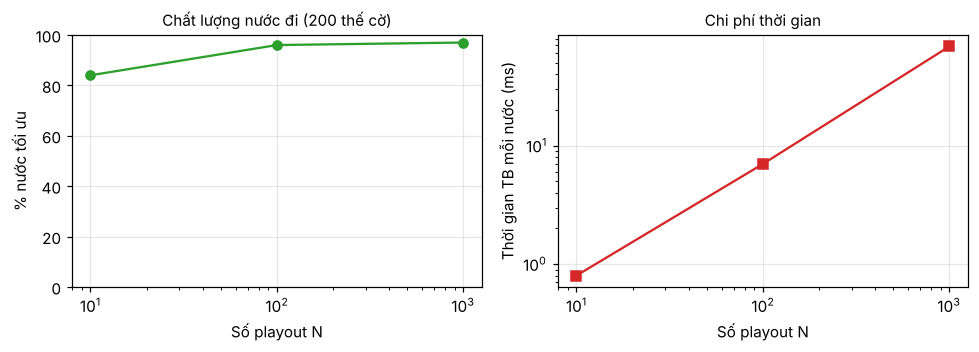

In [19]:
# ---- Chất lượng nước đi theo N trên 200 thế cờ "có phân biệt nước tốt/xấu" lấy ngẫu nhiên ----
start = tuple(empty_board())
reach, frontier = {start: 'x'}, [(start, 'x')]
while frontier:
    nxt = []
    for s, p in frontier:
        if check_board(list(s)) != 'n': continue
        for a in tictactoe.actions(list(s)):
            c = list(s); c[a] = p; c = tuple(c)
            if c not in reach:
                reach[c] = other(p); nxt.append((c, other(p)))
    frontier = nxt
informative_states = [(list(s), p) for s, p in reach.items()
                      if check_board(list(s)) == 'n' and optimal_set(list(s), p)[1]]
print(f"Có {len(informative_states):,} thế cờ chưa kết thúc mà các nước đi có giá trị Minimax khác nhau.")

sample = random.Random(2026).sample(informative_states, 200)
np.random.seed(2026)
qrows = []
for N in (10, 100, 1000):
    ok, ms = 0, 0.0
    for b, p in sample:
        opt, _ = optimal_set(b, p)
        t0 = time.perf_counter()
        a = pmcs(b, N = N, player = p)
        ms += (time.perf_counter() - t0) * 1000
        ok += (a in opt)
    qrows.append({"N": N, "% nước tối ưu": 100 * ok / len(sample), "Thời gian TB (ms)": ms / len(sample)})
q = pd.DataFrame(qrows).round(1)
display(q)

fig, ax = plt.subplots(1, 2, figsize = (9, 3.3), dpi = 110)
ax[0].plot(q["N"], q["% nước tối ưu"], marker = "o", color = "#2ca02c"); ax[0].set_xscale("log")
ax[0].set_xlabel("Số playout N"); ax[0].set_ylabel("% nước tối ưu"); ax[0].set_ylim(0, 100); ax[0].grid(alpha = .3)
ax[0].set_title("Chất lượng nước đi (200 thế cờ)", fontsize = 10)
ax[1].plot(q["N"], q["Thời gian TB (ms)"], marker = "s", color = "#d62728"); ax[1].set_xscale("log"); ax[1].set_yscale("log")
ax[1].set_xlabel("Số playout N"); ax[1].set_ylabel("Thời gian TB mỗi nước (ms)"); ax[1].grid(alpha = .3)
ax[1].set_title("Chi phí thời gian", fontsize = 10)
plt.tight_layout(); plt.show()

In [20]:
# ---- Bảng PMCS vs. Random: N = 10, 100, 1000 (mỗi vai 100 ván, seed cố định) ----
def timed(agent, stats):
    def f(board, player = 'x'):
        t = time.perf_counter(); a = agent(board, player)
        stats["t"] += time.perf_counter() - t; stats["n"] += 1
        return a
    return f

PLAYERS = {10: pmcs10_player, 100: pmcs100_player, 1000: pmcs1000_player}
GAMES = 100
np.random.seed(2026)
rows = []
for N, agent in PLAYERS.items():
    for role in ("x", "o"):
        st = {"t": 0.0, "n": 0}
        a = timed(agent, st)
        t0 = time.perf_counter()
        r = play(a, random_player, N = GAMES) if role == "x" else play(random_player, a, N = GAMES)
        wall = time.perf_counter() - t0
        win, loss = (r['x'], r['o']) if role == "x" else (r['o'], r['x'])
        rows.append({"N": N, "Vai": role, "Số ván": GAMES, "Thắng": win, "Hòa": r['d'], "Thua": loss,
                     "Thời gian TB / nước (ms)": round(1000 * st["t"] / st["n"], 2), "Tổng thời gian (s)": round(wall, 1),
                     "_t": st["t"], "_n": st["n"]})
pm = pd.DataFrame(rows)
display(pm.drop(columns = ["_t", "_n"]))

# Gộp hai vai (200 ván / mỗi N) – đúng dạng bảng của đề bài, kèm cột Nhận xét
vn = lambda x, d = 1: f"{x:.{d}f}".replace(".", ",")
final_rows = []
for N in PLAYERS:
    sub = pm[pm["N"] == N]
    games, w, d_, l = sub["Số ván"].sum(), sub["Thắng"].sum(), sub["Hòa"].sum(), sub["Thua"].sum()
    wx = int(sub[sub["Vai"] == "x"]["Thắng"].iloc[0]); wo = int(sub[sub["Vai"] == "o"]["Thắng"].iloc[0])
    final_rows.append({"Số playout N": N,
                       "Tỷ lệ thắng": f"{100 * w / games:.1f}%", "Tỷ lệ hòa": f"{100 * d_ / games:.1f}%", "Tỷ lệ thua": f"{100 * l / games:.1f}%",
                       "Thời gian TB / nước (ms)": round(1000 * sub["_t"].sum() / sub["_n"].sum(), 2),
                       "Nhận xét": f"Thắng {wx}% khi đi trước, {wo}% khi đi sau; thua {l}/{games} ván"})
final = pd.DataFrame(final_rows)
display(final)

,N,Vai,Số ván,Thắng,Hòa,Thua,Thời gian TB / nước (ms),Tổng thời gian (s)
0,10,x,100,90,4,6,1.98,0.7
1,10,o,100,69,10,21,1.42,0.5
2,100,x,100,99,1,0,14.38,4.9
3,100,o,100,90,5,5,12.00,3.9
4,1000,x,100,93,7,0,149.81,48.6
5,1000,o,100,91,5,4,118.42,38.2


,Số playout N,Tỷ lệ thắng,Tỷ lệ hòa,Tỷ lệ thua,Thời gian TB / nước (ms),Nhận xét
0,10,79.5%,7.0%,13.5%,1.71,"Thắng 90% khi đi trước, 69% khi đi sau; thua 2..."
1,100,94.5%,3.0%,2.5%,13.22,"Thắng 99% khi đi trước, 90% khi đi sau; thua 5..."
2,1000,92.0%,6.0%,2.0%,134.16,"Thắng 93% khi đi trước, 91% khi đi sau; thua 4..."


In [21]:
# Nhận xét tự động từ số liệu vừa đo (để luôn nhất quán với các bảng ở trên)
G = {r["Số playout N"]: r for r in final_rows}
win_rate = {N: float(G[N]["Tỷ lệ thắng"].rstrip("%")) for N in G}
loss_n   = {N: int(pm[pm["N"] == N]["Thua"].sum()) for N in G}
ms       = {N: G[N]["Thời gian TB / nước (ms)"] for N in G}
top_freq = stab.groupby("N")["freq"].mean()
opt_rows = stab[stab["% chọn nước tối ưu"] != "—"].copy()
opt_rows["p"] = opt_rows["% chọn nước tối ưu"].str.rstrip("%").astype(float)
opt_pct  = opt_rows.groupby("N")["p"].mean()
qual     = q.set_index("N")["% nước tối ưu"]

display(Markdown(f"""
**Nhận xét (số liệu của các ô có seed cố định ở trên).**

* **Độ ổn định tăng theo N.** Trong 30 lần chạy lặp lại, nước được chọn nhiều nhất chiếm trung bình {vn(top_freq[10], 0)} % số lần với N = 10, {vn(top_freq[100], 0)} % với N = 100 và {vn(top_freq[1000], 0)} % với N = 1000. Ở hai thế cờ có nước tối ưu phân biệt được (x sắp thắng, x cần tìm đường hòa), tỉ lệ chọn nước tối ưu là {vn(opt_pct[10], 0)} % → {vn(opt_pct[100], 0)} % → {vn(opt_pct[1000], 0)} % khi N = 10 → 100 → 1000; trên 200 thế cờ ngẫu nhiên là {vn(qual[10], 0)} % → {vn(qual[100], 0)} % → {vn(qual[1000], 0)} %.
* **Vì sao vẫn còn dao động ở N = 1000.** Có hai nguyên nhân: (i) các nước *tương đương* (ô 2 và 6 ở thế "o sắp thắng"; bốn góc ở bàn cờ rỗng) có kỳ vọng bằng nhau nên chọn nước nào cũng được; (ii) khi chênh lệch kỳ vọng nhỏ hơn sai số lấy mẫu – ở bàn cờ rỗng N = 1000 chỉ có ≈ 111 playout/nước nên sai số chuẩn ≈ 0,08, trong khi ô giữa hơn góc có 0,157 (0,5 so với 0,343) – nên ô giữa chỉ được chọn khoảng 2/3 số lần.
* **Sai số giảm theo 1/√n** (biểu đồ hội tụ): gấp 100 lần số playout chỉ giảm sai số khoảng 10 lần, vì vậy tăng N có hiệu quả giảm dần.
* **Thời gian tăng gần tuyến tính theo N:** khoảng {vn(ms[10], 2)} ms → {vn(ms[100], 1)} ms → {vn(ms[1000], 0)} ms mỗi nước đi (≈ ×10 mỗi lần nhân N với 10) vì mỗi playout có chi phí gần như nhau (thời gian tuyệt đối phụ thuộc máy chạy).
* **PMCS vs. Random.** Tỉ lệ thắng gộp hai vai là {vn(win_rate[10])} % (N = 10), {vn(win_rate[100])} % (N = 100) và {vn(win_rate[1000])} % (N = 1000); số ván thua trên 200 ván là {loss_n[10]} → {loss_n[100]} → {loss_n[1000]}. Tỉ lệ thắng tăng mạnh từ N = 10 lên N = 100 rồi gần như bão hòa (chênh lệch giữa N = 100 và N = 1000 nằm trong sai số thống kê của 200 ván, khoảng ±3 %), vì Random là đối thủ yếu nên ≈ 10 playout/nước đã đủ để tránh gần hết các nước sai; số ván hòa không giảm theo N vì PMCS tối ưu *điểm kỳ vọng trước đối thủ ngẫu nhiên* chứ không tối đa hóa số ván thắng.
* **Ưu điểm so với heuristic search:** không cần hàm đánh giá thủ công, dễ áp dụng cho trò chơi lớn. **Hạn chế:** không đảm bảo nước tối ưu, kết quả ngẫu nhiên giữa các lần chạy, thời gian tăng theo N và chất lượng phụ thuộc vào chính sách playout (ngẫu nhiên ⇒ đánh giá thế cờ như thể đối thủ chơi tệ).
"""))


**Nhận xét (số liệu của các ô có seed cố định ở trên).**

* **Độ ổn định tăng theo N.** Trong 30 lần chạy lặp lại, nước được chọn nhiều nhất chiếm trung bình 45 % số lần với N = 10, 68 % với N = 100 và 85 % với N = 1000. Ở hai thế cờ có nước tối ưu phân biệt được (x sắp thắng, x cần tìm đường hòa), tỉ lệ chọn nước tối ưu là 48 % → 90 % → 100 % khi N = 10 → 100 → 1000; trên 200 thế cờ ngẫu nhiên là 84 % → 96 % → 97 %.
* **Vì sao vẫn còn dao động ở N = 1000.** Có hai nguyên nhân: (i) các nước *tương đương* (ô 2 và 6 ở thế "o sắp thắng"; bốn góc ở bàn cờ rỗng) có kỳ vọng bằng nhau nên chọn nước nào cũng được; (ii) khi chênh lệch kỳ vọng nhỏ hơn sai số lấy mẫu – ở bàn cờ rỗng N = 1000 chỉ có ≈ 111 playout/nước nên sai số chuẩn ≈ 0,08, trong khi ô giữa hơn góc có 0,157 (0,5 so với 0,343) – nên ô giữa chỉ được chọn khoảng 2/3 số lần.
* **Sai số giảm theo 1/√n** (biểu đồ hội tụ): gấp 100 lần số playout chỉ giảm sai số khoảng 10 lần, vì vậy tăng N có hiệu quả giảm dần.
* **Thời gian tăng gần tuyến tính theo N:** khoảng 1,71 ms → 13,2 ms → 134 ms mỗi nước đi (≈ ×10 mỗi lần nhân N với 10) vì mỗi playout có chi phí gần như nhau (thời gian tuyệt đối phụ thuộc máy chạy).
* **PMCS vs. Random.** Tỉ lệ thắng gộp hai vai là 79,5 % (N = 10), 94,5 % (N = 100) và 92,0 % (N = 1000); số ván thua trên 200 ván là 27 → 5 → 4. Tỉ lệ thắng tăng mạnh từ N = 10 lên N = 100 rồi gần như bão hòa (chênh lệch giữa N = 100 và N = 1000 nằm trong sai số thống kê của 200 ván, khoảng ±3 %), vì Random là đối thủ yếu nên ≈ 10 playout/nước đã đủ để tránh gần hết các nước sai; số ván hòa không giảm theo N vì PMCS tối ưu *điểm kỳ vọng trước đối thủ ngẫu nhiên* chứ không tối đa hóa số ván thắng.
* **Ưu điểm so với heuristic search:** không cần hàm đánh giá thủ công, dễ áp dụng cho trò chơi lớn. **Hạn chế:** không đảm bảo nước tối ưu, kết quả ngẫu nhiên giữa các lần chạy, thời gian tăng theo N và chất lượng phụ thuộc vào chính sách playout (ngẫu nhiên ⇒ đánh giá thế cờ như thể đối thủ chơi tệ).
